<div style="text-align:center; line-height:1.6">

МИНИСТЕРСТВО НАУКИ И ВЫСШЕГО ОБРАЗОВАНИЯ РФ<br>
ФГБОУ ВО «Новосибирский государственный технический университет»<br>
Кафедра автоматизированных систем управления

# Лабораторная работа № 4
## «MLOps: учёт экспериментов, версионирование и развёртывание модели»

по дисциплине «Системы искусственного интеллекта и машинное обучение»<br>
**Вариант 9 — «Классификация риска низкой успеваемости»**

</div>

<div style="text-align:right">
Выполнил: студент гр. АВТ-313, АВТФ Зоркольцев Илья Алексеевич<br>
Проверил: ассистент каф. АСУ Антонянц Егор Николаевич
</div>

<div style="text-align:center">Новосибирск, 2026</div>

# 1. Цель работы и постановка задачи

**Цель:** освоить основы MLOps — учёт и сравнение экспериментов в MLflow, регистрацию и управление версиями моделей в Model Registry, развёртывание сервиса предсказаний с помощью Docker и Docker Compose, проверку его работоспособности, обновление и откат модели.

**Индивидуальный вариант 9 — классификация риска низкой успеваемости.** По данным об учащемся требуется предсказать, окажется ли итоговая оценка ниже порога: целевая переменная `risk = 1`, если `G3 < 10`, иначе `0`. Порог 10 задан условием варианта. Алгоритмы — LogisticRegression и RandomForestClassifier, основной критерий — macro F1 на validation.

Задачи: подготовить данные и зафиксировать разбиение; выполнить не менее шести экспериментов с записью параметров, метрик, тегов и артефактов в MLflow; выбрать модель; зарегистрировать версии в Model Registry и назначить alias `champion`; экспортировать модель вместе с preprocessing; развернуть API в Docker; проверить корректные и ошибочные запросы; показать обновление и откат без переобучения; запустить сервис через Docker Compose с healthcheck.

# 2. Описание набора данных

**Источник:** Cortez P. Student Performance, UCI Machine Learning Repository, dataset 320 (https://archive.ics.uci.edu/dataset/320/student+performance). Используется файл `student-mat.csv` (успеваемость по математике). Для контроля неизменности снимка вычислен хэш SHA-256, он сохранён в файле `data/raw/student-mat.sha256` (рисунок 1).

**Объём:** 395 строк и 33 столбца (рисунок 2): демографические и социальные признаки (`school`, `sex`, `age`, `address`, `famsize`, `Pstatus`), образование и работа родителей (`Medu`, `Fedu`, `Mjob`, `Fjob`), учебные факторы (`studytime`, `failures`, `schoolsup`, `paid`, `higher`, `absences` и др.), а также оценки за периоды `G1`, `G2` и итоговая `G3` (0–20, среднее 10,4, медиана 11).

**Целевая переменная:** `risk = (G3 < 10)`. Доля класса «риск» — **32,9 %** (130 из 395), классы несбалансированы, поэтому основной метрикой выбрана **macro F1**, а не accuracy.

**Подготовка данных:**

- `G3` используется только для построения цели и исключается из признаков; `G1` и `G2` также исключены — это промежуточные оценки того же курса, которые почти однозначно определяют итог и дали бы утечку информации. В X остаются 30 признаков.
- Пропусков в наборе нет; для устойчивости API preprocessing всё равно содержит заполнение пропусков. Числовые признаки масштабируются, категориальные кодируются one-hot (`handle_unknown="ignore"`). Все преобразования входят в `Pipeline` и обучаются только на train.
- **Разбиение 60/20/20 со стратификацией** по `risk` и фиксированным `random_state`: train 237, validation 79, test 79 объектов. Стратификация сохраняет долю класса «риск» ≈ 33 % в каждой части. Validation используется для выбора модели, test — только для итоговой оценки.

In [2]:
from IPython.display import Image
Image("screenshots/fig01.png")

FileNotFoundError: No such file or directory: 'screenshots/fig01.png'

FileNotFoundError: No such file or directory: 'screenshots/fig01.png'

<IPython.core.display.Image object>

*Рисунок 1 — Хэш SHA-256 исходного файла данных student-mat.csv*

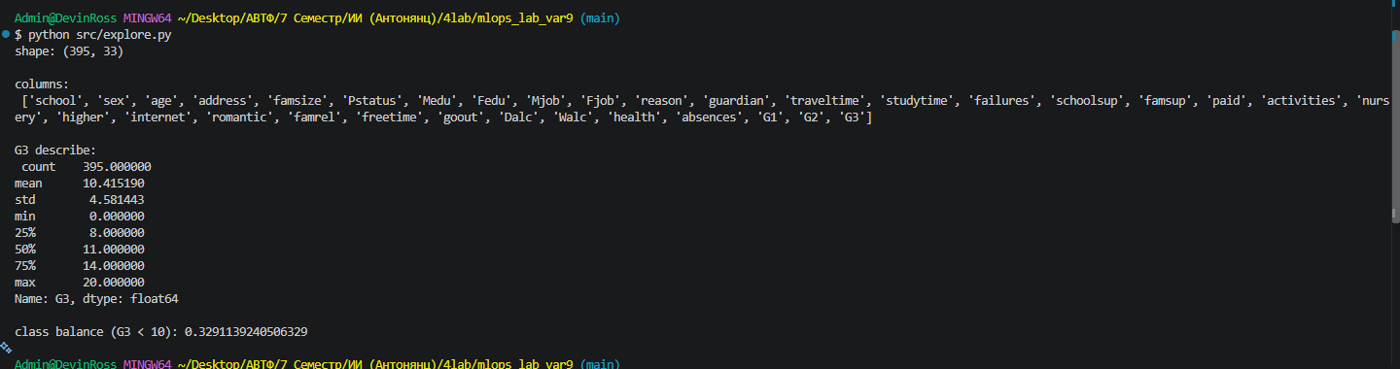

In [ ]:
from IPython.display import Image
Image("screenshots/fig02.png")

*Рисунок 2 — Разведочный анализ (explore.py): размер 395 × 33, распределение G3, доля класса «риск» 0,329*

# 3. Программное окружение

Работа выполнена в Windows (Git Bash, VS Code), виртуальное окружение `.venv`. Версии основных компонентов: **Python 3.12, MLflow 3.5.0, scikit-learn 1.7.2** (рисунок 3), FastAPI и Uvicorn для API, Docker и Docker Compose. Точные версии зависимостей зафиксированы в `requirements.txt`.

Сервер MLflow запускается локально на `127.0.0.1:5000`: метаданные хранятся в SQLite, модели и файлы — в локальной папке артефактов (рисунки 4, 5).

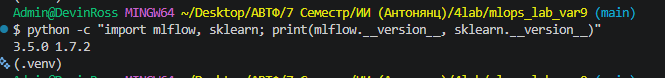

In [ ]:
from IPython.display import Image
Image("screenshots/fig03.png")

*Рисунок 3 — Проверка версий MLflow и scikit-learn в виртуальном окружении*

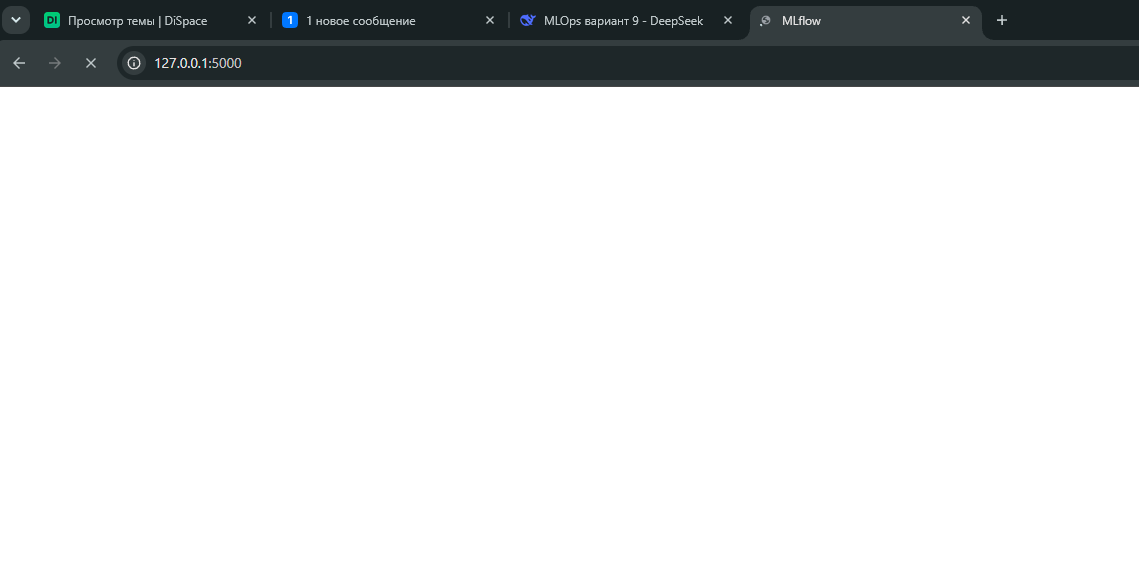

In [ ]:
from IPython.display import Image
Image("screenshots/fig04.png")

*Рисунок 4 — Запуск сервера MLflow*

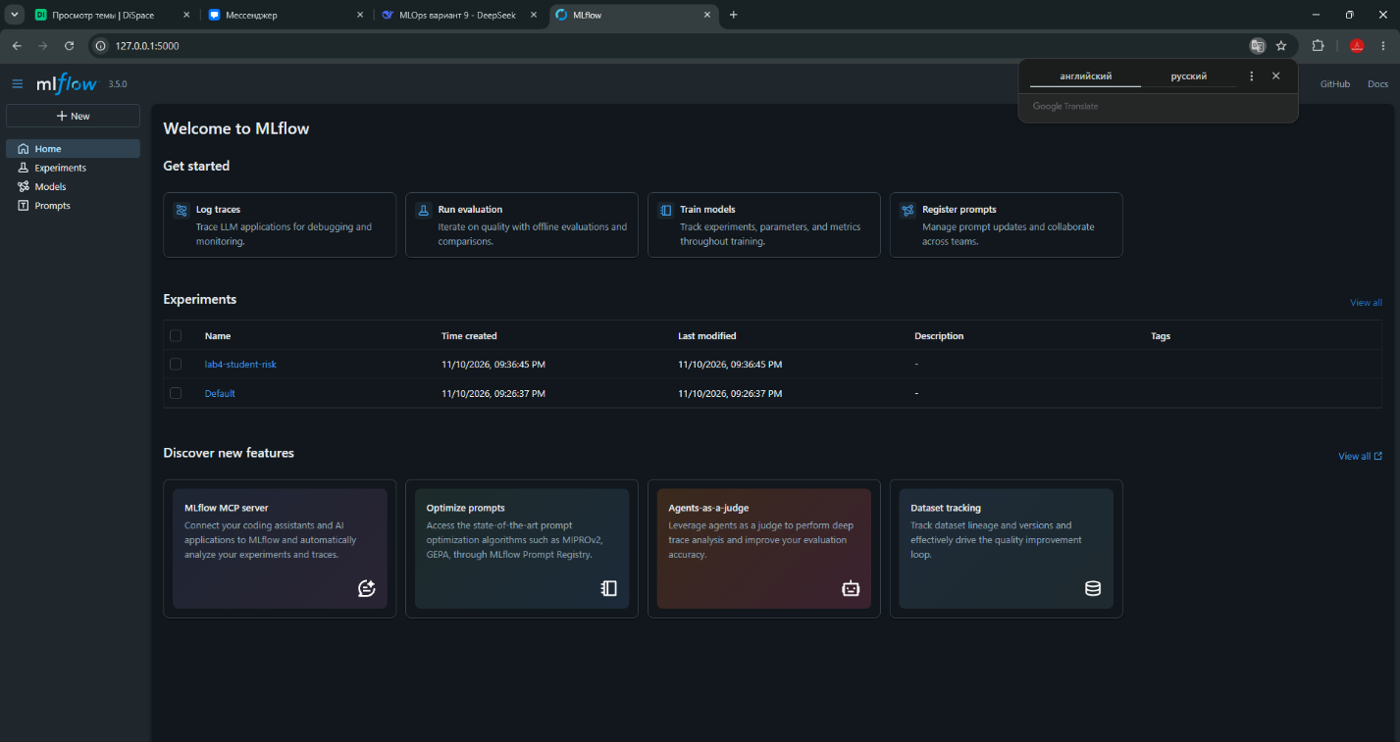

In [ ]:
from IPython.display import Image
Image("screenshots/fig05.png")

*Рисунок 5 — Интерфейс MLflow: создан эксперимент lab4-student-risk*

# 4. Эксперименты в MLflow

Скрипт `train.py` для каждого запуска загружает данные, применяет фиксированное разбиение, обучает Pipeline и записывает в MLflow параметры (алгоритм, `C` или `n_estimators` и `max_depth`), метрики на validation (`val_accuracy`, `val_f1_macro`), теги и артефакты (модель с signature, описание разбиения, код). Выполнено шесть основных запусков: LogisticRegression с C = 0,1; 1; 10 и RandomForest с (n_estimators, max_depth) = (50, 3); (100, 5); (200, 8). На рисунке 6 показаны шесть основных запусков (в строке поиска задан фильтр, неудачные запуски скрыты), на рисунке 7 — полная таблица с метриками, включая запуски для регистрации.

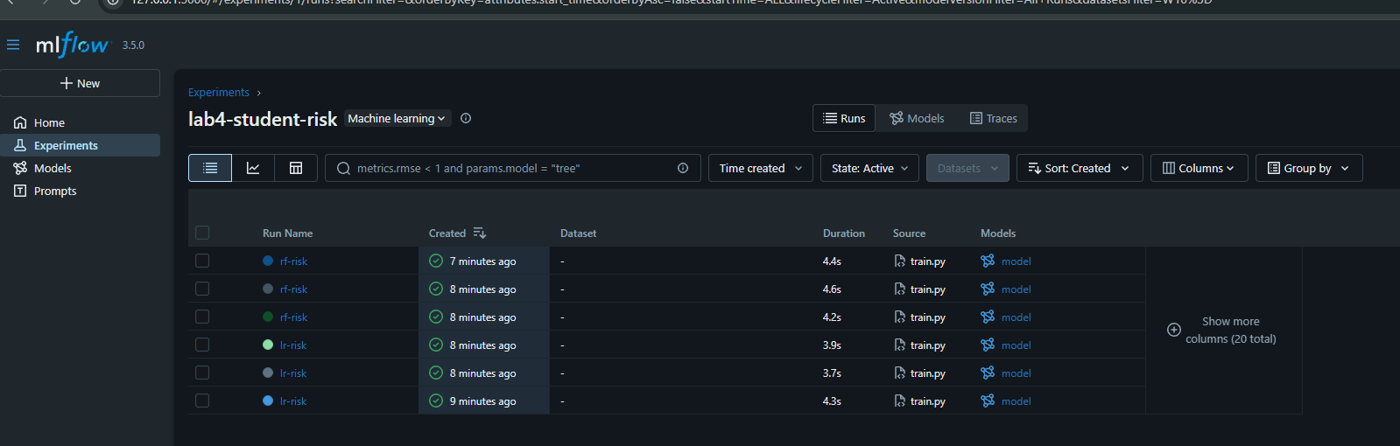

In [ ]:
from IPython.display import Image
Image("screenshots/fig06.png")

*Рисунок 6 — Шесть основных запусков в эксперименте lab4-student-risk*

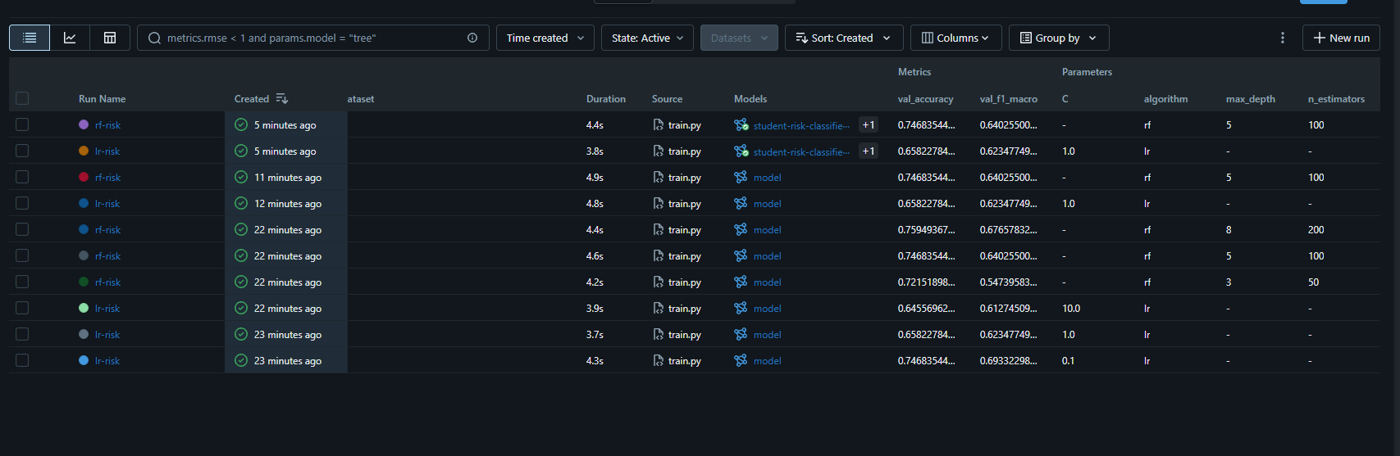

In [ ]:
from IPython.display import Image
Image("screenshots/fig07.png")

*Рисунок 7 — Все запуски с параметрами и validation-метриками*

**Таблица 1 — Сравнение шести экспериментов (validation, 79 объектов)**

| № | Алгоритм | Гиперпараметры | val_accuracy | val_f1_macro |
|---|---|---|---|---|
| 1 | **LogisticRegression** | **C = 0,1** | 0,747 | **0,693** |
| 2 | LogisticRegression | C = 1 | 0,658 | 0,623 |
| 3 | LogisticRegression | C = 10 | 0,646 | 0,613 |
| 4 | RandomForest | n_estimators = 50, max_depth = 3 | 0,722 | 0,547 |
| 5 | RandomForest | n_estimators = 100, max_depth = 5 | 0,747 | 0,640 |
| 6 | RandomForest | n_estimators = 200, max_depth = 8 | 0,759 | 0,677 |

**Обоснование выбора.** Лучший результат по основному критерию — **LogisticRegression с C = 0,1: val_f1_macro = 0,693**. У логистической регрессии усиление регуляризации (уменьшение C) улучшает качество: при 30 признаках и 237 объектах сильная регуляризация снижает переобучение. Случайный лес с глубиной 8 даёт чуть большую accuracy (0,759), но меньший macro F1 (0,677): он лучше угадывает преобладающий класс «нет риска» и хуже — класс «риск», который и важен в задаче. Поскольку F1 у лучших моделей сопоставим, решающими стали **простота и интерпретируемость** логистической регрессии: коэффициенты показывают, какие факторы (число неудач `failures`, пропуски `absences`, желание учиться дальше `higher` и др.) повышают риск. Поэтому выбрана LogisticRegression (C = 0,1).

# 5. Регистрация версий и экспорт модели

Выбранные конфигурации зарегистрированы в MLflow Model Registry под именем `student-risk-classifier`. В Registry три версии (рисунки 8, 9): версии 1 и 2 — модели из регистрационных запусков (RandomForest и LogisticRegression с C = 1), **версия 3 — выбранная LogisticRegression (C = 0,1)**. Версии 3 назначен **alias `champion`**. Alias — это указатель на конкретную версию: при его переназначении новая модель не создаётся.

Скрипт `export_model.py` находит модель по алиасу `champion` (Version 3), скачивает её из MLflow и сохраняет в папку `exported_model` вместе с `metadata.json` — номером версии, `run_id` (71bca806…) и списком признаков в нужном порядке (рисунок 10). В папке `exported_model` лежат `MLmodel`, `model.pkl` (весь Pipeline с preprocessing), `conda.yaml`, `python_env.yaml`, `requirements.txt` и `metadata.json` (рисунок 11).

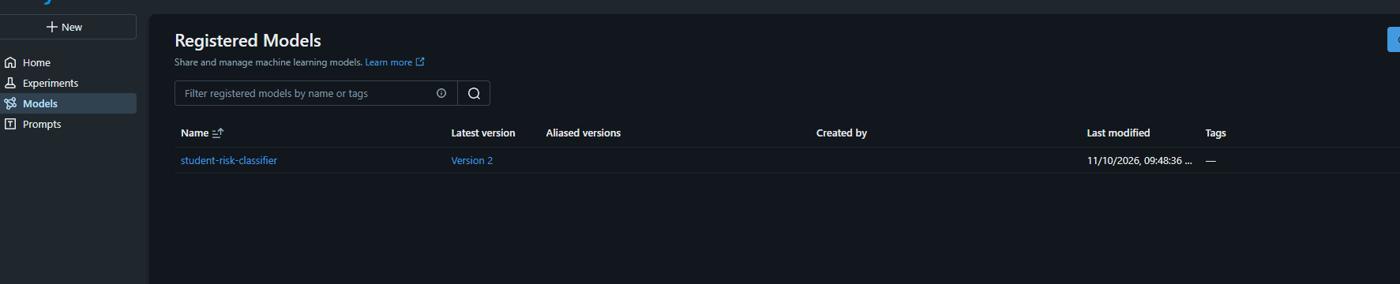

In [ ]:
from IPython.display import Image
Image("screenshots/fig08.png")

*Рисунок 8 — Model Registry: зарегистрированная модель student-risk-classifier*

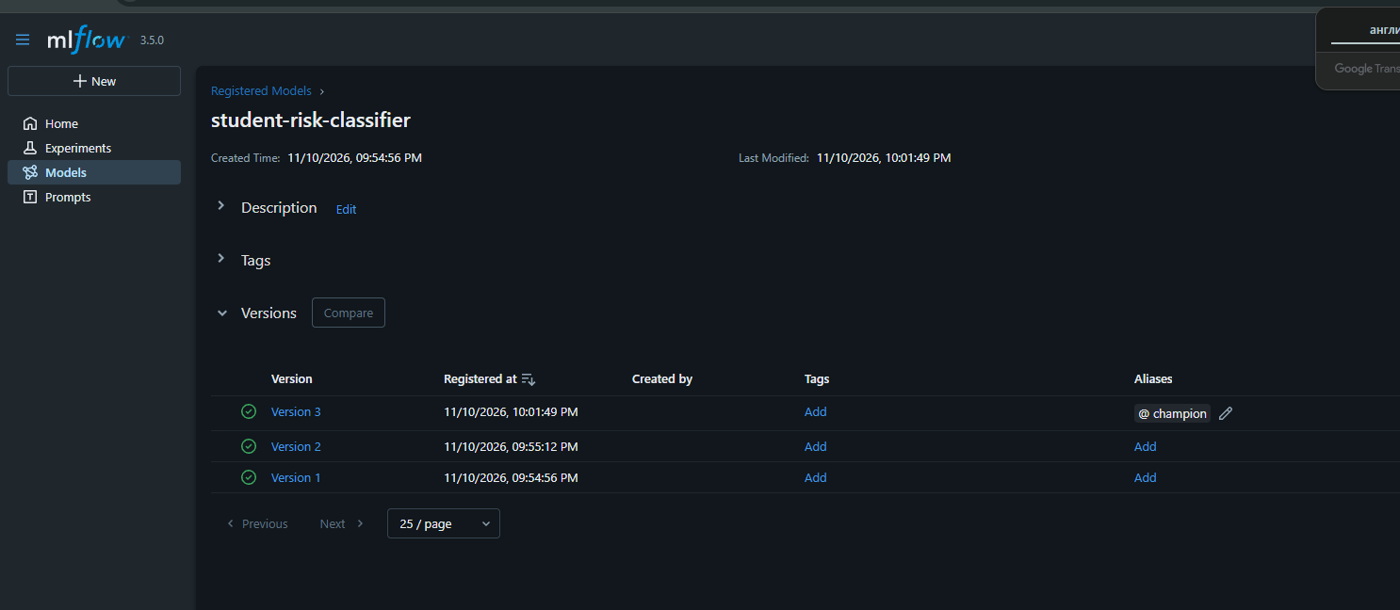

In [ ]:
from IPython.display import Image
Image("screenshots/fig09.png")

*Рисунок 9 — Три версии модели в Registry, версии 3 назначен alias champion*

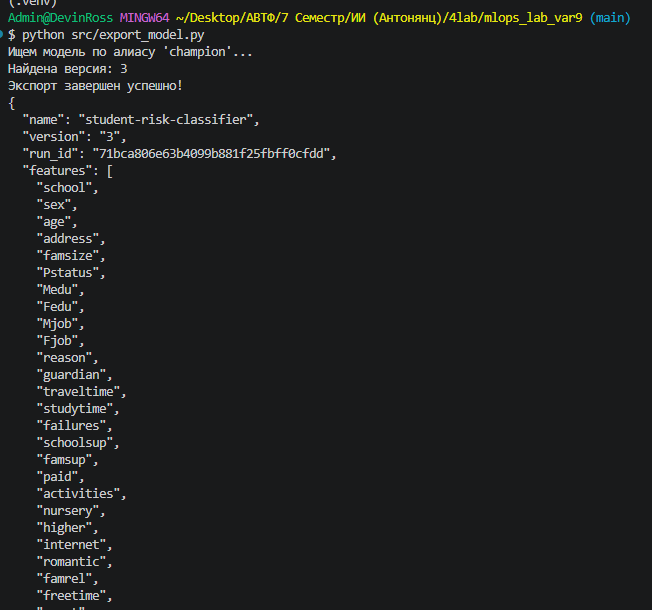

In [ ]:
from IPython.display import Image
Image("screenshots/fig10.png")

*Рисунок 10 — Экспорт модели по алиасу champion (Version 3) и содержимое metadata.json*

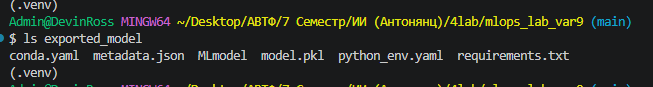

In [ ]:
from IPython.display import Image
Image("screenshots/fig11.png")

*Рисунок 11 — Содержимое папки exported_model*

# 6. Docker и API

API реализовано на FastAPI: `GET /health` — проверка, что приложение запущено и модель загружена; `GET /metadata` — версия модели и порядок признаков; `POST /predict` — предсказание для пакета объектов в формате `{"instances": [{...}, ...]}`; ответ содержит предсказанные классы риска и версию модели. Модель загружается из `exported_model` один раз при старте, к серверу MLflow API не обращается.

Dockerfile основан на образе `python:3.12-slim`: устанавливает зависимости, копирует код API и папку `exported_model`, запускает `uvicorn` на `0.0.0.0:8000`. Образ успешно собран командой `docker build -t student-api:v1 .` и запущен как контейнер `student-api` с публикацией порта 8000 (рисунок 12). Запросы `/health` и `/predict` возвращают код 200.

**Проверка ошибочного запроса.** На пустой пакет `{"instances": []}` FastAPI успешно отклонил некорректный запрос, вернув **422 Unprocessable Entity** с пояснением `too_short: List should have at least 1 item after validation` (рисунки 13, 14). Ошибка 500 не возникает — валидация входа выполняется схемой Pydantic до обращения к модели.

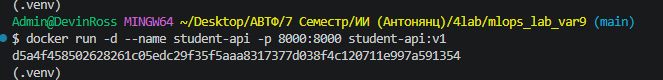

In [ ]:
from IPython.display import Image
Image("screenshots/fig12.png")

*Рисунок 12 — Запуск контейнера student-api из образа student-api:v1*

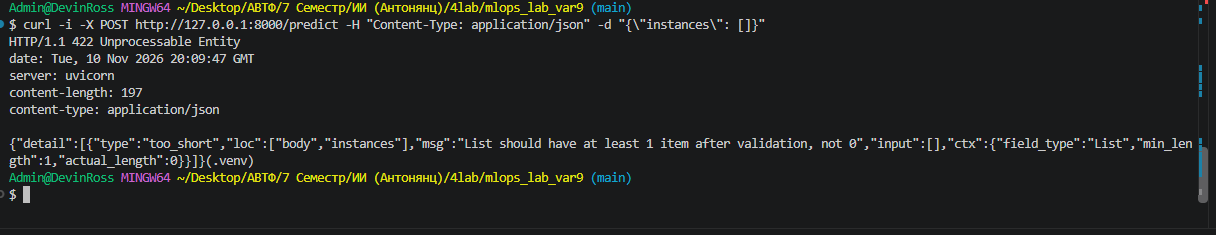

In [ ]:
from IPython.display import Image
Image("screenshots/fig13.png")

*Рисунок 13 — FastAPI отклонил некорректный запрос (пустой пакет), вернув 422 Unprocessable Entity*

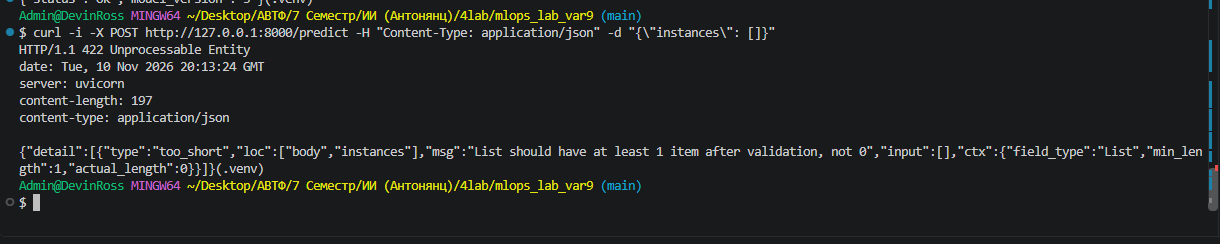

In [ ]:
from IPython.display import Image
Image("screenshots/fig14.png")

*Рисунок 14 — Повторная проверка ошибочного запроса после перезапуска сервиса: 422*

# 7. Обновление, откат и Docker Compose

**Обновление.** Для демонстрации доставки выпущен образ с тегом `student-api:v2`: контейнер `student-api` остановлен и удалён, затем запущен из образа v2 (рисунки 15, 16). В учебной имитации образ v2 получен командой `docker tag student-api:v1 student-api:v2`, то есть содержит ту же модель; отрабатывается сам порядок выпуска новой версии сервиса.

**Откат.** Контейнер v2 остановлен и удалён, сервис снова запущен из сохранённого образа `student-api:v1` (рисунки 17, 18). Откат выполняется без переобучения и без пересборки: предыдущий образ хранится локально, и достаточно перезапустить контейнер из него. `docker ps` подтверждает, что работает `student-api:v1`.

**Docker Compose.** Файл `compose.yaml` описывает сервис `api` на образе `student-api:v1`, публикацию порта 8000 и healthcheck — периодический запрос к `/health` внутри контейнера. После `docker compose up -d` контейнер сначала имеет статус `health: starting` (рисунок 19), а после первой успешной проверки — **`Up (healthy)`** (рисунок 20). Это подтверждает, что сервис запущен и модель загружена.

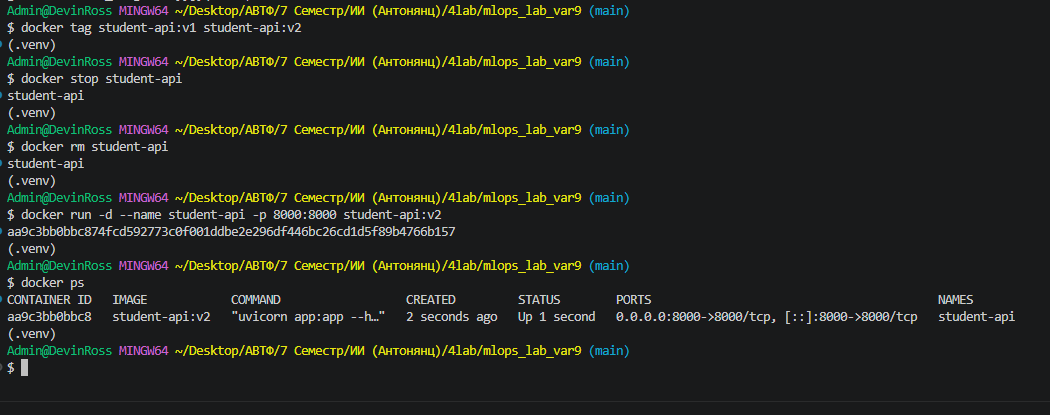

In [ ]:
from IPython.display import Image
Image("screenshots/fig15.png")

*Рисунок 15 — Обновление: запуск сервиса из образа student-api:v2*

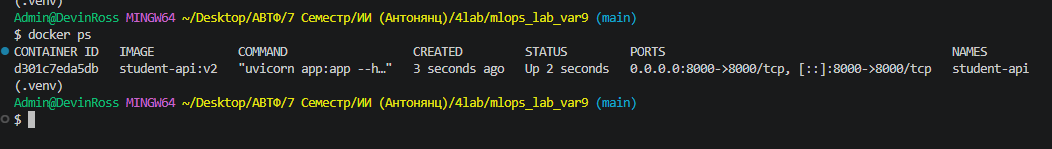

In [ ]:
from IPython.display import Image
Image("screenshots/fig16.png")

*Рисунок 16 — docker ps: работает контейнер из образа student-api:v2*

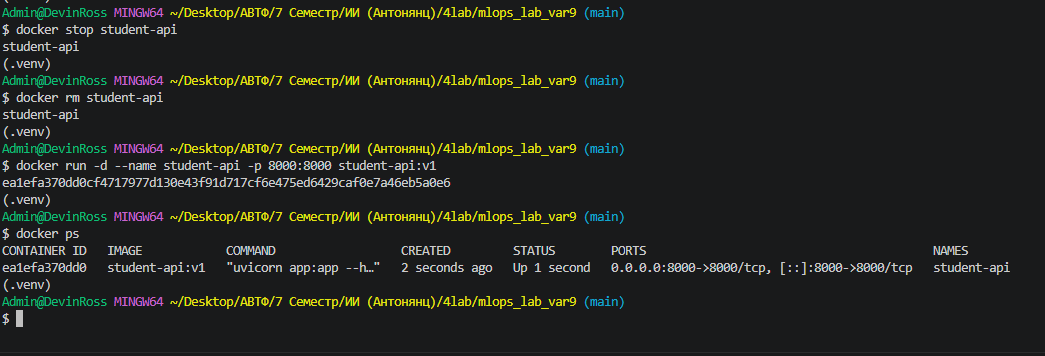

In [ ]:
from IPython.display import Image
Image("screenshots/fig17.png")

*Рисунок 17 — Откат: сервис снова запущен из образа student-api:v1*

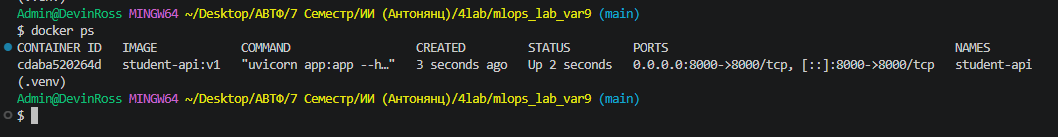

In [ ]:
from IPython.display import Image
Image("screenshots/fig18.png")

*Рисунок 18 — docker ps после отката: работает student-api:v1*

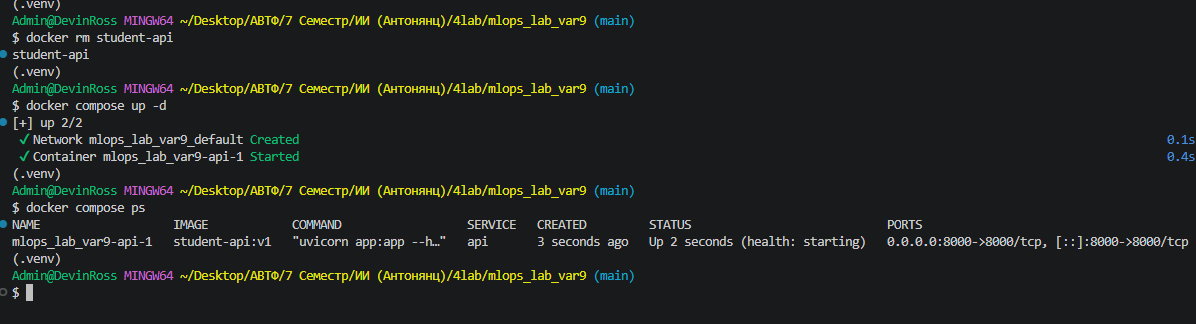

In [ ]:
from IPython.display import Image
Image("screenshots/fig19.png")

*Рисунок 19 — Запуск через Docker Compose: статус health: starting*

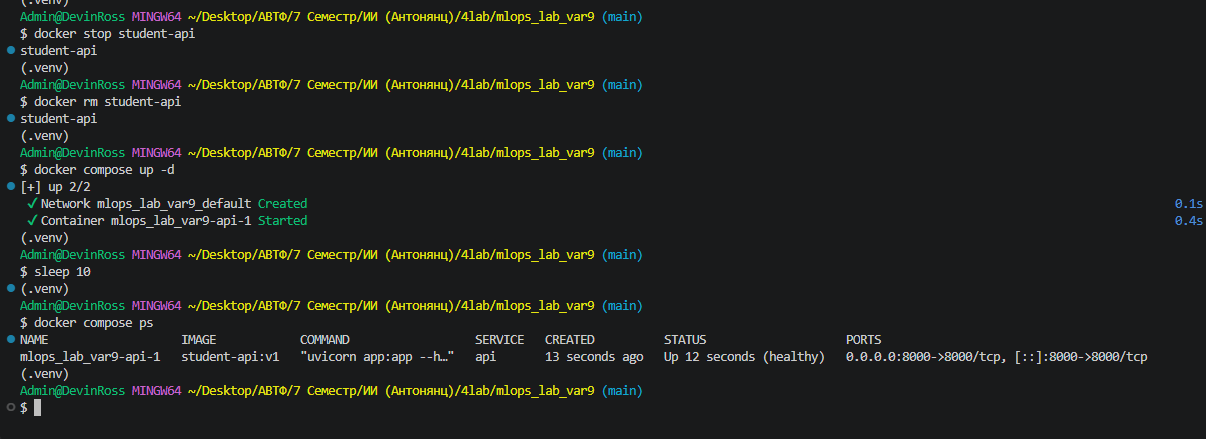

In [ ]:
from IPython.display import Image
Image("screenshots/fig20.png")

*Рисунок 20 — Docker Compose: контейнер в статусе Up (healthy)*

# 8. Выводы

1. Построен воспроизводимый цикл ML-проекта для варианта 9: зафиксированный снимок данных (SHA-256), стратифицированное разбиение 60/20/20, исключение G1/G2/G3 из признаков, эксперименты в MLflow, Registry, экспорт, API, Docker, откат и Compose.
2. Из шести экспериментов лучшей по macro F1 оказалась LogisticRegression (C = 0,1): val_f1_macro = 0,693. Случайный лес даёт сопоставимое качество (до 0,677), но логистическая регрессия проще и интерпретируемее, поэтому выбрана она.
3. Model Registry с алиасом `champion` отделяет выбор модели от её доставки: экспорт берёт ту версию, на которую указывает alias (Version 3), а версия и `run_id` сохраняются в `metadata.json`.
4. Сервис в Docker корректно обрабатывает запросы и отклоняет некорректные (422). Хранение тегированных образов позволяет откатиться к предыдущей версии без переобучения и пересборки, а Docker Compose с healthcheck запускает сервис одной командой и показывает его состояние (`healthy`).

# 9. Список источников

1. Cortez P., Silva A. Using Data Mining to Predict Secondary School Student Performance. UCI Machine Learning Repository, Student Performance, dataset 320. https://archive.ics.uci.edu/dataset/320/student+performance
2. MLflow Documentation: Tracking, Model Registry, Aliases. https://mlflow.org/docs/latest/
3. scikit-learn Documentation: Pipeline, LogisticRegression, RandomForestClassifier. https://scikit-learn.org/stable/
4. FastAPI Documentation. https://fastapi.tiangolo.com/
5. Docker Documentation: Dockerfile, Docker Compose, Healthcheck. https://docs.docker.com/
6. Методические указания к лабораторной работе 4 «MLOps». НГТУ, 2026.

# Приложение. Исходный код

Код проекта находится в репозитории: `src/train.py`, `src/app.py`, `src/export_model.py`, `Dockerfile`, `requirements.txt`, `compose.yaml`. Основные файлы выводятся ячейками ниже.

In [ ]:
!cat src/train.py

In [ ]:
!cat src/app.py

In [ ]:
!cat Dockerfile

In [ ]:
!cat requirements.txt

In [ ]:
!cat compose.yaml